In [1]:
%pip install tensorflow numpy pandas matplotlib scikit-learn pillow tqdm streamlit certifi torch "transformers>=4.40,<5"

  Obtaining dependency information for torch from https://files.pythonhosted.org/packages/d1/7e/7f1252812e8048bc24f203fc0757a251f26af797b4ff986e19046e2b5f73/torch-2.15.0-cp311-cp311-win_amd64.whl.metadata
  Obtaining dependency information for transformers<5,>=4.40 from https://files.pythonhosted.org/packages/03/b8/e484ef633af3887baeeb4b6ad12743363af7cce68ae51e938e00aaa0529d/transformers-4.57.6-py3-none-any.whl.metadata
     ---------------------------------------- 0.0/44.0 kB ? eta -:--:--
     ---------------------------------------- 44.0/44.0 kB 1.1 MB/s eta 0:00:00
  Obtaining dependency information for filelock from https://files.pythonhosted.org/packages/b7/8d/3f849fcb79359259737bc2d8ddcaee6149ffb773239a260c9ff20179736f/filelock-4.2.6-py3-none-any.whl.metadata
  Obtaining dependency information for setuptools from https://files.pythonhosted.org/packages/ef/55/6dc6d6bb953bdfc52519a0059592c52b6e3b8ad51cf8256dffceb55b0610/setuptools-84.2.1-py3-none-any.whl.metadata
  Obtaining depen

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, json, time, hashlib, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

warnings.filterwarnings('ignore')

In [3]:
# ============ KONFIGURASI PRAKTIKUM ============
# Ganti path ini sesuai lokasi folder dataset di komputer.
# Bisa juga mengatur environment variable DATASET_DIR.
DATASET_DIR = os.environ.get(
    "DATASET_DIR",
    r"C:\Users\ASUS\Downloads\Klasifikasi_Image_Menggunakan_CNN\OceanicLife Dataset"
)
OUT_DIR = "output"

# Kelas objek laut. Label awal dibuat otomatis dengan CLIP (zero-shot),
# sehingga WAJIB ditinjau dan dikoreksi manual bila memungkinkan.
ALL_CLASSES = [
    "other", "fish", "seal", "coral", "crab",
    "shark", "turtle", "octopus", "starfish", "jellyfish"
]
CLASS_NAMES = list(ALL_CLASSES)

IMG_SIZE = (160, 160)
BATCH = 32
EPOCHS = 15
FINE_TUNE_EPOCHS = 10
SEED = 42

# Split akhir: 80% train, 10% validation, 10% test.
TEST_SIZE = 0.20
VAL_SIZE_FROM_HOLDOUT = 0.50

CLIP_MODEL = "openai/clip-vit-base-patch32"
CLIP_BATCH = 32
CONF_THRESHOLD = 0.45
RERUN_CLIP = False

USE_CLASS_WEIGHT = True
WEIGHTS = "imagenet"

# Gambar hasil resize disimpan PER FOLDER KELAS: output/resized_160/<kelas>/<gambar>.jpg
PROC_DIR = os.path.join(OUT_DIR, f"resized_{IMG_SIZE[0]}")
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(PROC_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    import certifi
    os.environ["SSL_CERT_FILE"] = certifi.where()
    os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()
except Exception:
    pass

ROOT = Path(DATASET_DIR).expanduser()
if not ROOT.exists():
    raise FileNotFoundError(
        f"Folder dataset tidak ditemukan: {ROOT}\n"
        "Ubah DATASET_DIR pada cell konfigurasi agar menunjuk ke folder dataset."
    )

print("Dataset :", ROOT.resolve())
print("Output  :", os.path.abspath(OUT_DIR))
print("TensorFlow:", tf.__version__)


Dataset : C:\Users\ASUS\Downloads\Klasifikasi_Image_Menggunakan_CNN\OceanicLife Dataset
Output  : c:\Users\ASUS\Downloads\Klasifikasi_Image_Menggunakan_CNN\output
TensorFlow: 2.21.0


In [4]:
EXTS = {".jpg", ".jpeg", ".png", ".gif", ".bmp", ".webp"}
META_CSV = os.path.join(OUT_DIR, "meta.csv")
SCAN_JSON = os.path.join(OUT_DIR, "scan_info.json")

def inspect_image(p):
    rec = {"path": p.relative_to(ROOT).as_posix(), "ok": False}
    try:
        rec["md5"] = hashlib.md5(p.read_bytes()).hexdigest()
        rec["size_kb"] = p.stat().st_size / 1024
        with Image.open(p) as im:
            rec.update(width=im.width, height=im.height, mode=im.mode, format=im.format)
            im.load()
            gray = np.asarray(
                ImageOps.exif_transpose(im).convert("L").resize((128, 128)),
                dtype=np.float32
            )
        lap = (4 * gray[1:-1, 1:-1] - gray[:-2, 1:-1] - gray[2:, 1:-1]
               - gray[1:-1, :-2] - gray[1:-1, 2:])
        rec["brightness"] = float(gray.mean())
        rec["sharpness"] = float(lap.var())
        rec["ok"] = True
    except Exception as exc:
        rec["error"] = str(exc)[:160]
    return rec

all_files = sorted(
    p for p in ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in EXTS
)
print(f"Total file gambar ditemukan: {len(all_files)}")
if not all_files:
    raise RuntimeError(
        "Tidak ada gambar pada folder dataset. Pastikan DATASET_DIR menunjuk "
        "ke folder yang berisi subfolder kelas atau file gambar."
    )

# Cache hanya dipakai bila masih cocok dengan isi folder dataset.
use_cache = False
if os.path.exists(META_CSV) and os.path.exists(SCAN_JSON):
    try:
        cached = pd.read_csv(META_CSV)
        cached_paths = set(cached["path"].astype(str))
        current_paths = {p.relative_to(ROOT).as_posix() for p in all_files}
        use_cache = cached_paths == current_paths and len(cached) > 0
    except Exception:
        use_cache = False

if use_cache:
    meta = cached
    scan_info = json.load(open(SCAN_JSON, encoding="utf-8"))
    print("Metadata dimuat dari cache.")
else:
    raw = pd.DataFrame([
        inspect_image(p) for p in tqdm(all_files, desc="Memeriksa gambar")
    ])
    n_corrupt = int((~raw["ok"]).sum())
    raw = raw[raw["ok"]].copy()
    n_duplicates = int(raw.duplicated("md5").sum())
    meta = raw.drop_duplicates("md5").reset_index(drop=True)
    scan_info = {
        "n_files": len(all_files), "n_corrupt": n_corrupt,
        "n_duplicates": n_duplicates, "n_valid": len(meta)
    }
    meta.to_csv(META_CSV, index=False)
    with open(SCAN_JSON, "w", encoding="utf-8") as f:
        json.dump(scan_info, f, indent=2)

print("File korup dibuang     :", scan_info["n_corrupt"])
print("Duplikat persis dibuang:", scan_info["n_duplicates"])
print("Gambar valid dipakai   :", len(meta))
display(meta.head())


Total file gambar ditemukan: 7998


Memeriksa gambar:   0%|          | 0/7998 [00:00<?, ?it/s]

File korup dibuang     : 8
Duplikat persis dibuang: 6956
Gambar valid dipakai   : 1034


,path,ok,md5,size_kb,width,height,mode,format,brightness,sharpness,error
0,001v5h0d.jpg,True,930b3e0f6f5ebc26c6700cb15c67070a,30.307617,518,713,RGB,JPEG,48.797424,3787.050049,NaN
1,002ojjl6.jpg,True,45dcfa980d33405dcadca0cf3a4fbcf9,28.564453,563,296,RGB,JPEG,100.004700,886.697327,NaN
2,00dx9zud.JPG,True,4618aa10e8f291540dbdfbe38ef43094,2270.700195,3264,2448,RGB,JPEG,100.015747,2188.038330,NaN
3,00gohyw5.jpg,True,200bd0d68776f2f41116dc951373db23,87.990234,500,334,RGB,JPEG,97.042603,1187.128784,NaN
4,00lvn4tu.gif,True,e6da8735243dcdbd3be7e3659aae129f,59.236328,387,262,P,GIF,91.478210,10505.287109,NaN


In [5]:
PROMPTS = {
    'fish':      ['fish', 'a school of fish', 'a tropical reef fish', 'a fish swimming underwater', 'a colorful fish'],
    'seal':      ['a seal', 'a sea lion', 'a seal swimming underwater', 'a seal resting on rocks', 'a fur seal'],
    'coral':     ['coral', 'a coral reef', 'hard coral underwater', 'soft coral', 'colorful corals on a reef'],
    'crab':      ['a crab', 'a crab on the sea floor', 'a hermit crab', 'a crab on rocks', 'a close-up of a crab'],
    'shark':     ['a shark', 'a shark swimming underwater', 'a great white shark', 'a reef shark', 'a whale shark'],
    'turtle':    ['a sea turtle', 'a turtle swimming underwater', 'a green sea turtle', 'a turtle on a beach'],
    'octopus':   ['an octopus', 'an octopus underwater', 'an octopus with tentacles', 'a camouflaged octopus'],
    'starfish':  ['a starfish', 'a sea star', 'a starfish on the sea floor', 'a starfish on sand'],
    'jellyfish': ['a jellyfish', 'a jellyfish floating in the water', 'a glowing jellyfish', 'a transparent jellyfish'],
    'other':     ['a whale', 'a dolphin', 'a stingray', 'a manta ray', 'a sea urchin', 'a seahorse',
                  'a sea anemone', 'a lobster', 'a shrimp', 'a squid', 'an eel', 'a sea snail', 'a nudibranch',
                  'a sea cucumber', 'a penguin', 'a seabird', 'seaweed or kelp', 'a sponge',
                  'an empty underwater scene', 'a scuba diver', 'a boat on the sea', 'a beach or coastline',
                  'a person', 'an illustration or diagram'],
}
TEMPLATE = 'a photo of {}'
RAW_CSV = os.path.join(OUT_DIR, 'clip_probs.csv')

if os.path.exists(RAW_CSV) and not RERUN_CLIP:
    clip_df = pd.read_csv(RAW_CSV)
    expected_cols = ['path'] + [f'p_{c}' for c in ALL_CLASSES]
    cache_ok = (set(expected_cols).issubset(clip_df.columns)
                and clip_df['path'].astype(str).tolist() == meta['path'].astype(str).tolist())
    if not cache_ok:
        print('Cache CLIP tidak sesuai dataset/kelas; menghitung ulang.')
        clip_df = None
    else:
        print('Hasil CLIP dimuat dari cache:', RAW_CSV)
else:
    clip_df = None

if clip_df is None:
    import torch
    from transformers import CLIPModel, CLIPProcessor

    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print('Device:', device)
    clip = CLIPModel.from_pretrained(CLIP_MODEL).to(device).eval()
    proc = CLIPProcessor.from_pretrained(CLIP_MODEL)

    def as_tensor(o):
        if torch.is_tensor(o):
            return o
        for a in ('image_embeds', 'text_embeds', 'pooler_output'):
            v = getattr(o, a, None)
            if v is not None:
                return v
        raise TypeError(f'Output CLIP tidak dikenali: {type(o)}')

    texts, owner = [], []
    for ci, cname in enumerate(ALL_CLASSES):
        for p in PROMPTS[cname]:
            texts.append(TEMPLATE.format(p)); owner.append(ci)
    owner = np.array(owner)

    with torch.no_grad():
        t_in = proc(text=texts, return_tensors='pt', padding=True).to(device)
        t_feat = as_tensor(clip.get_text_features(**t_in))
        t_feat = t_feat / t_feat.norm(dim=-1, keepdim=True)
        scale = clip.logit_scale.exp()

    paths = meta['path'].tolist()
    probs_all = []
    for i in tqdm(range(0, len(paths), CLIP_BATCH), desc='CLIP zero-shot'):
        ims = []
        for rp in paths[i:i + CLIP_BATCH]:
            with Image.open(ROOT / rp) as im:
                ims.append(ImageOps.exif_transpose(im).convert('RGB'))
        with torch.no_grad():
            px = proc(images=ims, return_tensors='pt')['pixel_values'].to(device)
            f = as_tensor(clip.get_image_features(pixel_values=px))
            f = f / f.norm(dim=-1, keepdim=True)
            logits = (scale * f @ t_feat.T).cpu().numpy()          # (B, jumlah_prompt)
        cls_logits = np.stack([logits[:, owner == c].max(axis=1) for c in range(len(ALL_CLASSES))], axis=1)
        e = np.exp(cls_logits - cls_logits.max(axis=1, keepdims=True))
        probs_all.append(e / e.sum(axis=1, keepdims=True))

    P = np.concatenate(probs_all)
    clip_df = pd.DataFrame(P, columns=[f'p_{c}' for c in ALL_CLASSES])
    clip_df.insert(0, 'path', paths)
    clip_df.to_csv(RAW_CSV, index=False)
    print('Disimpan:', RAW_CSV)

clip_df.head()

Device: cpu


config.json: 0.00B [00:00, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP zero-shot:   0%|          | 0/33 [00:00<?, ?it/s]

Disimpan: output\clip_probs.csv


,path,p_other,p_fish,p_seal,p_coral,p_crab,p_shark,p_turtle,p_octopus,p_starfish,p_jellyfish
0,001v5h0d.jpg,0.972289,0.000626,1.812442e-05,0.001920,0.001169,0.000142,0.000086,0.000052,0.005467,1.823276e-02
1,002ojjl6.jpg,0.634034,0.009630,1.541962e-05,0.266752,0.000320,0.000006,0.000449,0.002717,0.011648,7.442856e-02
2,00dx9zud.JPG,0.001193,0.000023,1.038592e-07,0.000527,0.000498,0.000006,0.000001,0.001758,0.995987,6.263670e-06
3,00gohyw5.jpg,0.001421,0.992581,4.808833e-05,0.005718,0.000111,0.000048,0.000015,0.000021,0.000037,3.849437e-07
4,00lvn4tu.gif,0.180842,0.089824,2.589917e-04,0.018059,0.499461,0.000878,0.021464,0.145232,0.043932,4.757400e-05


In [6]:
# ---- ubah probabilitas CLIP -> label akhir (cepat, boleh diulang setelah mengubah CONF_THRESHOLD) ----
prob_cols = [f'p_{c}' for c in ALL_CLASSES]
P = clip_df[prob_cols].values
order = np.argsort(-P, axis=1)
lab = clip_df[['path']].copy()
lab['clip_label'] = [ALL_CLASSES[i] for i in order[:, 0]]
lab['clip_conf'] = P[np.arange(len(P)), order[:, 0]]
lab['clip_label2'] = [ALL_CLASSES[i] for i in order[:, 1]]
lab['clip_conf2'] = P[np.arange(len(P)), order[:, 1]]
lab['label'] = np.where(lab['clip_conf'] >= CONF_THRESHOLD, lab['clip_label'], 'other')

# (opsional) koreksi manual: buat output/label_overrides.csv dengan kolom: path,label
OVR = os.path.join(OUT_DIR, 'label_overrides.csv')
if os.path.exists(OVR):
    ovr = pd.read_csv(OVR)
    if not {'path', 'label'}.issubset(ovr.columns):
        raise ValueError('label_overrides.csv wajib memiliki kolom path dan label.')
    invalid = sorted(set(ovr['label'].dropna()) - set(ALL_CLASSES))
    if invalid:
        raise ValueError(f'Label manual tidak dikenal: {invalid}. Pilih dari {ALL_CLASSES}')
    lab = lab.merge(ovr[['path', 'label']].rename(columns={'label': 'label_manual'}),
                    on='path', how='left')
    lab['label'] = lab['label_manual'].fillna(lab['label'])
    lab = lab.drop(columns='label_manual')
    print(f'{ovr["label"].notna().sum()} label dikoreksi manual dari {OVR}')

data = meta.merge(lab, on='path', how='inner').reset_index(drop=True)
CLASS_NAMES = [c for c in ALL_CLASSES if (data['label'] == c).any()]       # buang kelas kosong
NUM_CLASSES = len(CLASS_NAMES)
if NUM_CLASSES < len(ALL_CLASSES):
    print('⚠️ Kelas tanpa gambar dibuang:', [c for c in ALL_CLASSES if c not in CLASS_NAMES])

data.to_csv(os.path.join(OUT_DIR, 'labels.csv'), index=False)
json.dump(CLASS_NAMES, open(os.path.join(OUT_DIR, 'class_names.json'), 'w'))

cnt = data['label'].value_counts().reindex(CLASS_NAMES)
print(cnt.to_string())
print(f'\nTotal: {len(data)} gambar | {NUM_CLASSES} kelas | '
      f'{(lab["clip_conf"] < CONF_THRESHOLD).sum()} gambar dialihkan ke "other" karena confidence rendah')
small = cnt[cnt < 30]
if len(small):
    print('⚠️ Kelas dengan <30 gambar (model sulit belajar):', small.to_dict(),
          '\n   Saran: turunkan CONF_THRESHOLD, tambah prompt, atau gabungkan ke "other".')

label
other        406
fish         265
seal          68
coral         62
crab          33
shark         62
turtle        38
octopus       33
starfish      34
jellyfish     33

Total: 1034 gambar | 10 kelas | 51 gambar dialihkan ke "other" karena confidence rendah


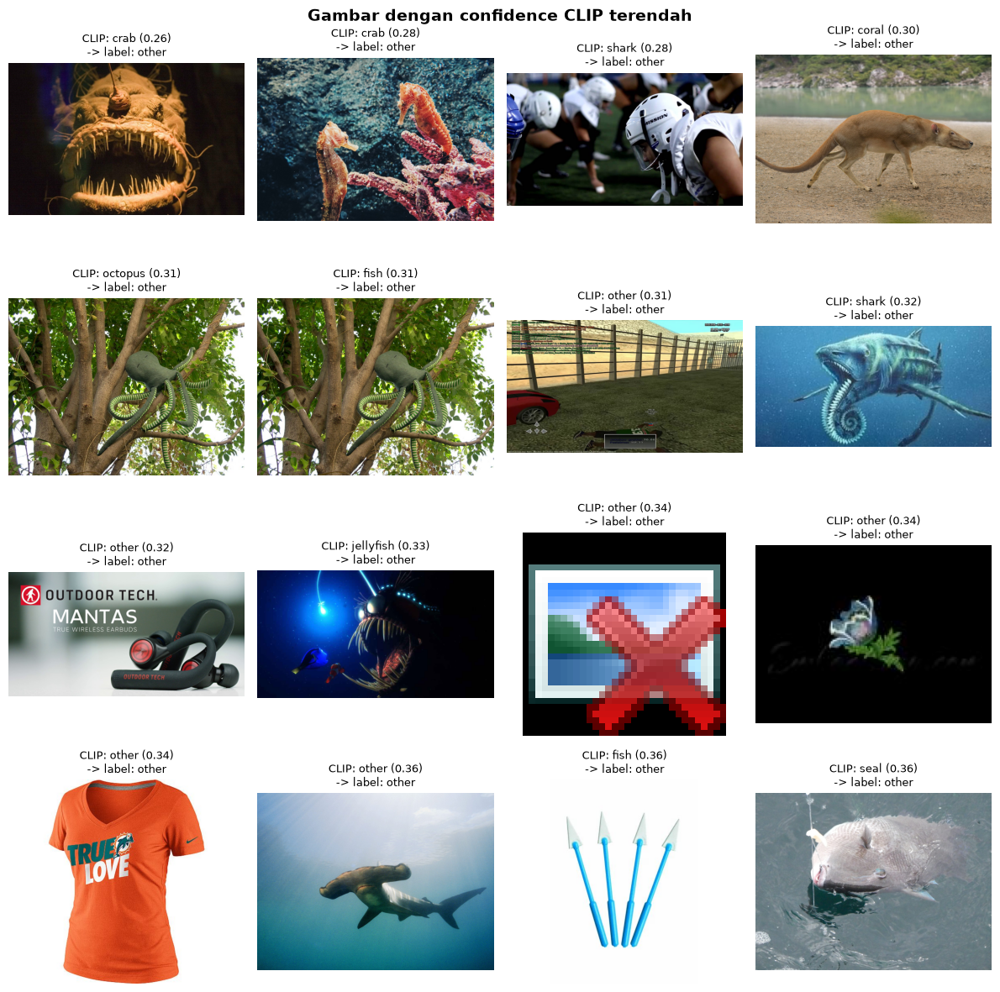

In [7]:
low = data.sort_values('clip_conf').head(16)
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for a, (_, r) in zip(axes.ravel(), low.iterrows()):
    with Image.open(ROOT / r['path']) as im:
        a.imshow(ImageOps.exif_transpose(im).convert('RGB'))
    a.set_title(f"CLIP: {r['clip_label']} ({r['clip_conf']:.2f})\n-> label: {r['label']}", fontsize=9)
    a.axis('off')
plt.suptitle('Gambar dengan confidence CLIP terendah', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '0_label_review_lowconf.png'), dpi=110, bbox_inches='tight')
plt.show()

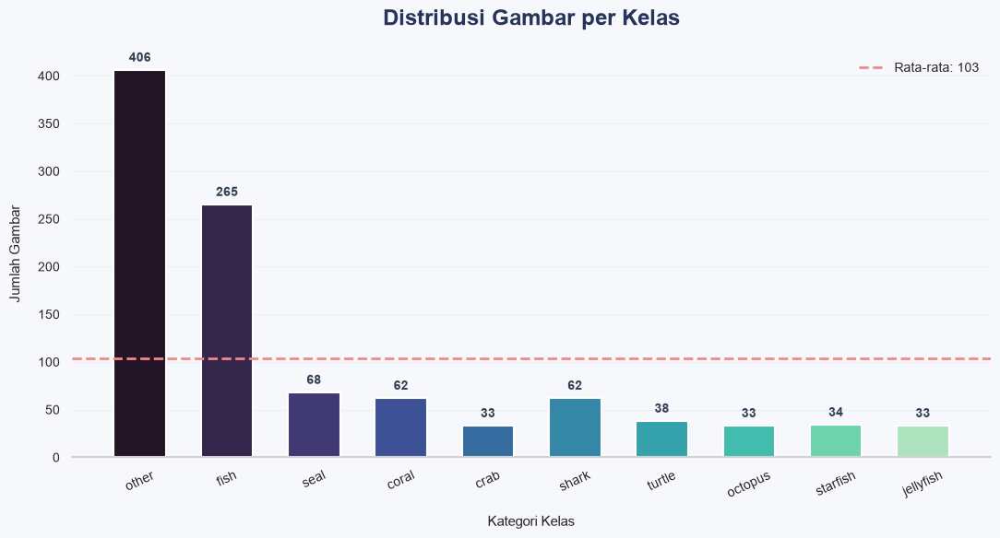

       HASIL ANALISIS DISTRIBUSI DATA
Kelas terbanyak  : other (406)
Kelas tersedikit : crab (33)
Rasio imbalance  : 12.30x
Kondisi data     : sangat tidak seimbang


In [9]:

# ==========================================
# VISUALISASI DISTRIBUSI JUMLAH GAMBAR
# ==========================================

import os
import matplotlib.pyplot as plt
import seaborn as sns

# Menghitung jumlah gambar setiap kelas
counts = data['label'].value_counts().reindex(CLASS_NAMES).fillna(0)

counts.rename('jumlah').to_csv(
    os.path.join(OUT_DIR, 'class_counts.csv'),
    header=True
)

imb_ratio = counts.max() / counts[counts > 0].min()

# Style grafik
sns.set_theme(style="whitegrid", font="sans-serif")

fig, ax = plt.subplots(figsize=(11, 6))
fig.patch.set_facecolor('#F7F8FC')
ax.set_facecolor('#F7F8FC')

# Warna setiap kelas
palette = sns.color_palette("mako", len(counts))

bars = ax.bar(
    counts.index,
    counts.values,
    color=palette,
    width=0.6,
    edgecolor='white',
    linewidth=1.5
)

# Garis rata-rata
ax.axhline(
    counts.mean(),
    color='#F08A8A',
    linestyle='--',
    linewidth=2,
    label=f'Rata-rata: {counts.mean():.0f}'
)

# Label jumlah di atas batang
for bar, value in zip(bars, counts.values):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + counts.max()*0.015,
        f'{int(value):,}',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        color='#344054'
    )

# Pengaturan grafik
ax.set_title(
    'Distribusi Gambar per Kelas',
    fontsize=17,
    fontweight='bold',
    color='#26345C',
    pad=20
)

ax.set_xlabel('Kategori Kelas', fontsize=11, labelpad=12)
ax.set_ylabel('Jumlah Gambar', fontsize=11, labelpad=12)

ax.tick_params(axis='x', rotation=25, labelsize=10)
ax.tick_params(axis='y', labelsize=10)

ax.legend(frameon=False, fontsize=10)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.grid(axis='y', alpha=0.2)
ax.grid(axis='x', visible=False)

plt.tight_layout()

# Simpan grafik
plt.savefig(
    os.path.join(OUT_DIR, '1_class_distribution.png'),
    dpi=300,
    bbox_inches='tight',
    facecolor=fig.get_facecolor()
)

plt.show()

# Analisis imbalance
level = (
    'relatif seimbang' if imb_ratio < 1.5
    else 'tidak seimbang sedang' if imb_ratio < 3
    else 'sangat tidak seimbang'
)

print('=' * 45)
print('       HASIL ANALISIS DISTRIBUSI DATA')
print('=' * 45)
print(f'Kelas terbanyak  : {counts.idxmax()} ({counts.max()})')
print(f'Kelas tersedikit : {counts.idxmin()} ({counts.min()})')
print(f'Rasio imbalance  : {imb_ratio:.2f}x')
print(f'Kondisi data     : {level}')
print('=' * 45)


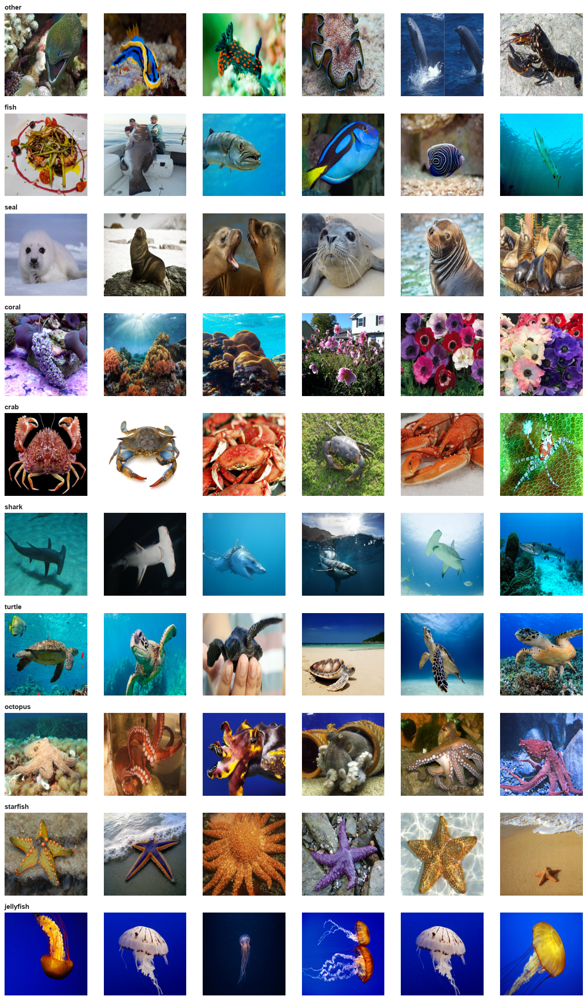

In [10]:
rng = np.random.default_rng(SEED)
N_PER = 6
fig, axes = plt.subplots(NUM_CLASSES, N_PER, figsize=(N_PER * 2.2, NUM_CLASSES * 2.2))
for r, c in enumerate(CLASS_NAMES):
    sub = data[data['label'] == c]
    pick = sub.sample(min(N_PER, len(sub)), random_state=SEED)
    for k in range(N_PER):
        a = axes[r, k]; a.axis('off')
        if k < len(pick):
            with Image.open(ROOT / pick.iloc[k]['path']) as im:
                a.imshow(ImageOps.exif_transpose(im).convert('RGB').resize((200, 200)))
        if k == 0:
            a.set_title(c, fontsize=11, fontweight='bold', loc='left')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '2_sample_per_class.png'), dpi=100, bbox_inches='tight')
plt.show()

        width  height  size_kb  brightness  sharpness
count  1034.0  1034.0   1034.0      1034.0     1034.0
mean   1225.4   891.8    363.1       106.9     1820.5
std     850.4   632.3    693.0        40.0     1549.4
min      32.0    32.0      1.7         6.2        6.5
25%     640.0   480.0     64.5        82.2      716.7
50%    1024.0   720.0    147.3       104.6     1456.6
75%    1600.0  1067.0    355.5       128.2     2410.1
max    6144.0  4378.0   8785.6       246.2    18371.2

Mode warna : {'RGB': 1011, 'RGBA': 14, 'P': 8, 'L': 1}
Format file: {'JPEG': 992, 'PNG': 30, 'WEBP': 7, 'GIF': 4, 'MPO': 1}
Flag kualitas: {'low_res (<160 px)': 8, 'gelap (brightness<40)': 41, 'terlalu terang (>215)': 22, 'blur (5% paling tidak tajam, <249)': 52}


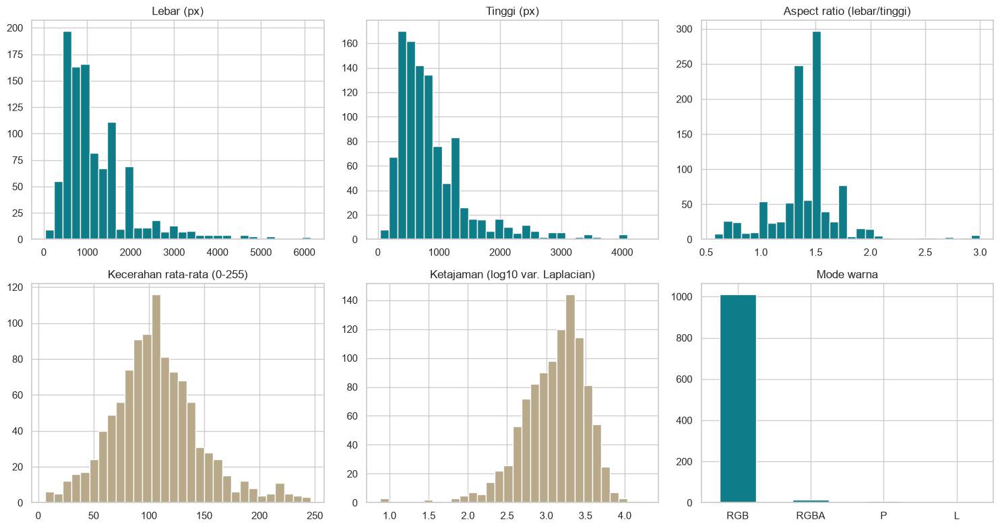

In [11]:
data['aspect'] = data['width'] / data['height']
data['min_side'] = data[['width', 'height']].min(axis=1)
blur_thr = float(np.percentile(data['sharpness'], 5))
flags = {
    'low_res (<160 px)': int((data['min_side'] < IMG_SIZE[0]).sum()),
    'gelap (brightness<40)': int((data['brightness'] < 40).sum()),
    'terlalu terang (>215)': int((data['brightness'] > 215).sum()),
    f'blur (5% paling tidak tajam, <{blur_thr:.0f})': int((data['sharpness'] < blur_thr).sum()),
}
eda = {
    'n_images': int(len(data)),
    'n_corrupt': scan_info['n_corrupt'], 'n_duplicates': scan_info['n_duplicates'],
    'width_median': float(data['width'].median()), 'height_median': float(data['height'].median()),
    'width_min': int(data['width'].min()), 'width_max': int(data['width'].max()),
    'height_min': int(data['height'].min()), 'height_max': int(data['height'].max()),
    'modes': data['mode'].value_counts().to_dict(),
    'formats': data['format'].value_counts().to_dict(),
    'aspect_median': float(data['aspect'].median()),
    'quality_flags': flags,
    'brightness_mean': float(data['brightness'].mean()),
}
json.dump(eda, open(os.path.join(OUT_DIR, 'eda_summary.json'), 'w'), indent=2)

print(data[['width', 'height', 'size_kb', 'brightness', 'sharpness']].describe().round(1).to_string())
print('\nMode warna :', eda['modes'])
print('Format file:', eda['formats'])
print('Flag kualitas:', flags)

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax[0, 0].hist(data['width'], bins=30, color='#0F7C8A'); ax[0, 0].set_title('Lebar (px)')
ax[0, 1].hist(data['height'], bins=30, color='#0F7C8A'); ax[0, 1].set_title('Tinggi (px)')
ax[0, 2].hist(data['aspect'].clip(0, 3), bins=30, color='#0F7C8A'); ax[0, 2].set_title('Aspect ratio (lebar/tinggi)')
ax[1, 0].hist(data['brightness'], bins=30, color='#B8A98A'); ax[1, 0].set_title('Kecerahan rata-rata (0-255)')
ax[1, 1].hist(np.log10(data['sharpness'] + 1), bins=30, color='#B8A98A'); ax[1, 1].set_title('Ketajaman (log10 var. Laplacian)')
pd.Series(eda['modes']).plot.bar(ax=ax[1, 2], color='#0F7C8A'); ax[1, 2].set_title('Mode warna'); ax[1, 2].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '3_image_stats.png'), dpi=110, bbox_inches='tight')
plt.show()

In [12]:
# ============ EKSPOR DATA PENELITIAN TERNORMALISASI ============
# Normalisasi citra dilakukan saat pipeline tf.data (piksel / 255).
# CSV ini berisi metadata numerik yang diskalakan Min-Max untuk analisis,
# sedangkan kolom label/path tetap dipertahankan.
from sklearn.preprocessing import MinMaxScaler

data_normalized = data.copy()
exclude_cols = {
    "label", "path", "proc_path", "md5", "format", "mode",
    "clip_label", "clip_label2"
}
numeric_cols = [
    col for col in data.select_dtypes(include=[np.number]).columns
    if col not in exclude_cols
]
scaler = MinMaxScaler()
if numeric_cols:
    data_normalized[numeric_cols] = scaler.fit_transform(data[numeric_cols])

NORMALIZED_CSV = os.path.join(OUT_DIR, "dataset_normalized.csv")
data_normalized.to_csv(NORMALIZED_CSV, index=False)
print("CSV penelitian tersimpan:", os.path.abspath(NORMALIZED_CSV))
print("Fitur metadata dinormalisasi:", numeric_cols)
display(data_normalized.head())


CSV penelitian tersimpan: c:\Users\ASUS\Downloads\Klasifikasi_Image_Menggunakan_CNN\output\dataset_normalized.csv
Fitur metadata dinormalisasi: ['size_kb', 'width', 'height', 'brightness', 'sharpness', 'clip_conf', 'clip_conf2', 'aspect', 'min_side']


,path,ok,md5,size_kb,width,height,mode,format,brightness,sharpness,error,clip_label,clip_conf,clip_label2,clip_conf2,label,aspect,min_side
0,001v5h0d.jpg,True,930b3e0f6f5ebc26c6700cb15c67070a,0.003255,0.079516,0.156696,RGB,JPEG,0.177429,0.205858,NaN,other,0.962389,jellyfish,0.036742,other,0.025528,0.111827
1,002ojjl6.jpg,True,45dcfa980d33405dcadca0cf3a4fbcf9,0.003056,0.086878,0.060746,RGB,JPEG,0.390779,0.047928,NaN,other,0.502467,coral,0.538015,other,0.225695,0.060746
2,00dx9zud.JPG,True,4618aa10e8f291540dbdfbe38ef43094,0.258313,0.528796,0.555913,RGB,JPEG,0.390825,0.118788,NaN,starfish,0.994610,octopus,0.003513,starfish,0.128858,0.555913
3,00gohyw5.jpg,True,200bd0d68776f2f41116dc951373db23,0.009821,0.076571,0.069489,RGB,JPEG,0.378438,0.064287,NaN,fish,0.989980,coral,0.011499,fish,0.156728,0.069489
4,00lvn4tu.gif,True,e6da8735243dcdbd3be7e3659aae129f,0.006548,0.058082,0.052922,P,GIF,0.355255,0.571681,NaN,crab,0.319489,other,0.364732,crab,0.153338,0.052922


In [13]:
# ============ RESIZE, SPLIT TRAIN/VALIDATION/TEST, DAN PIPELINE ============
def resize_save(relative_path, md5, label):
    """Resize gambar lalu simpan ke output/resized_160/<label>/<nama_asli>_<md5>.jpg"""
    class_dir = os.path.join(PROC_DIR, label)
    os.makedirs(class_dir, exist_ok=True)
    out_path = os.path.join(class_dir, f"{Path(relative_path).stem}_{md5[:8]}.jpg")
    if not os.path.exists(out_path):
        with Image.open(ROOT / relative_path) as im:
            im = (ImageOps.exif_transpose(im).convert("RGB")
                  .resize(IMG_SIZE, Image.Resampling.LANCZOS))
            im.save(out_path, format="JPEG", quality=95)
    return os.path.abspath(out_path)

# Pastikan SEMUA kelas punya folder (walau kosong), seperti struktur dataset per-kelas
for c in CLASS_NAMES:
    os.makedirs(os.path.join(PROC_DIR, c), exist_ok=True)

data["proc_path"] = [
    resize_save(row.path, row.md5, row.label)
    for row in tqdm(data.itertuples(), total=len(data), desc="Resize gambar -> folder per kelas")
]

# Bersihkan file lama yang tidak lagi dipakai (mis. label berubah setelah CONF_THRESHOLD/override diubah)
_keep = set(data["proc_path"])
for _p in Path(PROC_DIR).rglob("*.jpg"):
    if os.path.abspath(_p) not in _keep:
        _p.unlink()

print("Gambar hasil resize tersimpan per folder kelas di:", os.path.abspath(PROC_DIR))
for c in CLASS_NAMES:
    n = len(list((Path(PROC_DIR) / c).glob("*.jpg")))
    print(f"  {c:<10s}: {n} gambar")
data["label_idx"] = data["label"].map({name: i for i, name in enumerate(CLASS_NAMES)}).astype(int)

# Agar setiap kelas terwakili pada ketiga subset, minimal perlu 3 sampel/kelas.
counts = data["label"].value_counts().reindex(CLASS_NAMES, fill_value=0)
if (counts < 10).any():
    raise ValueError(
        "Setiap kelas disarankan memiliki minimal 10 gambar agar split train/validation/test terstratifikasi. "
        f"Kelas bermasalah: {counts[counts < 10].to_dict()}. "
        "Tambahkan data atau koreksi/gabungkan kelas melalui output/label_overrides.csv."
    )

train_df, holdout_df = train_test_split(
    data, test_size=TEST_SIZE, stratify=data["label_idx"], random_state=SEED
)
val_df, test_df = train_test_split(
    holdout_df, test_size=1 - VAL_SIZE_FROM_HOLDOUT,
    stratify=holdout_df["label_idx"], random_state=SEED
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

split_tbl = pd.DataFrame({
    "train": train_df["label"].value_counts(),
    "validation": val_df["label"].value_counts(),
    "test": test_df["label"].value_counts()
}).reindex(CLASS_NAMES).fillna(0).astype(int)
split_tbl["total"] = split_tbl.sum(axis=1)
split_tbl.to_csv(os.path.join(OUT_DIR, "split_counts.csv"))
split_records = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="validation"),
    test_df.assign(split="test")
])
split_records[["path", "label", "split"]].to_csv(
    os.path.join(OUT_DIR, "split.csv"), index=False
)
print(split_tbl.to_string())
print(
    f"\\nTrain: {len(train_df)} ({len(train_df)/len(data):.1%})"
    f" | Validation: {len(val_df)} ({len(val_df)/len(data):.1%})"
    f" | Test: {len(test_df)} ({len(test_df)/len(data):.1%})"
)

AUTOTUNE = tf.data.AUTOTUNE

def _decode(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    return tf.cast(image, tf.float32), label

def make_ds(frame, training=False):
    labels = np.eye(NUM_CLASSES, dtype=np.float32)[frame["label_idx"].values]
    ds = tf.data.Dataset.from_tensor_slices(
        (frame["proc_path"].astype(str).values, labels)
    )
    ds = ds.map(_decode, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.shuffle(
            buffer_size=max(len(frame), 1), seed=SEED,
            reshuffle_each_iteration=True
        )
    ds = ds.batch(BATCH).map(
        lambda x, y: (x / 255.0, y),
        num_parallel_calls=AUTOTUNE
    )
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(train_df, training=True)
val_ds = make_ds(val_df, training=False)
test_ds = make_ds(test_df, training=False)

if USE_CLASS_WEIGHT:
    class_weights = compute_class_weight(
        class_weight="balanced",
        classes=np.arange(NUM_CLASSES),
        y=train_df["label_idx"].values
    )
    class_weight = {i: float(w) for i, w in enumerate(class_weights)}
    print("Class weight:", {
        CLASS_NAMES[i]: round(weight, 3)
        for i, weight in class_weight.items()
    })
else:
    class_weight = None


Resize gambar -> folder per kelas:   0%|          | 0/1034 [00:00<?, ?it/s]

Gambar hasil resize tersimpan per folder kelas di: c:\Users\ASUS\Downloads\Klasifikasi_Image_Menggunakan_CNN\output\resized_160
  other     : 406 gambar
  fish      : 265 gambar
  seal      : 68 gambar
  coral     : 62 gambar
  crab      : 33 gambar
  shark     : 62 gambar
  turtle    : 38 gambar
  octopus   : 33 gambar
  starfish  : 34 gambar
  jellyfish : 33 gambar
           train  validation  test  total
label                                    
other        325          40    41    406
fish         212          26    27    265
seal          54           7     7     68
coral         50           6     6     62
crab          26           3     4     33
shark         50           6     6     62
turtle        30           4     4     38
octopus       27           3     3     33
starfish      27           4     3     34
jellyfish     26           4     3     33
\nTrain: 827 (80.0%) | Validation: 103 (10.0%) | Test: 104 (10.1%)
Class weight: {'other': 0.254, 'fish': 0.39, 'seal': 1.531,

Lokasi: c:\Users\ASUS\Downloads\Klasifikasi_Image_Menggunakan_CNN\output\resized_160


,folder,jumlah_gambar
0,coral,62
1,crab,33
2,fish,265
3,jellyfish,33
4,octopus,33
5,other,406
6,seal,68
7,shark,62
8,starfish,34
9,turtle,38


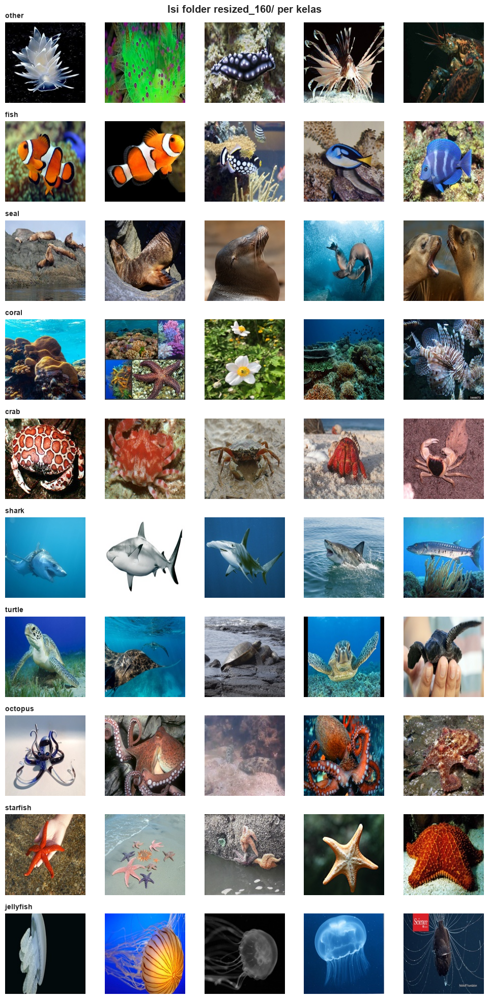

In [14]:
rows = []
for d in sorted(Path(PROC_DIR).iterdir()):
    if d.is_dir():
        rows.append({'folder': d.name, 'jumlah_gambar': len(list(d.glob('*.jpg')))})
folder_df = pd.DataFrame(rows)
folder_df.to_csv(os.path.join(OUT_DIR, 'resized_folder_counts.csv'), index=False)
print('Lokasi:', os.path.abspath(PROC_DIR))
display(folder_df)

# contoh 1 baris gambar per folder kelas
N_SHOW = 5
fig, axes = plt.subplots(len(CLASS_NAMES), N_SHOW, figsize=(N_SHOW * 2, len(CLASS_NAMES) * 2), squeeze=False)
for r, c in enumerate(CLASS_NAMES):
    files = sorted((Path(PROC_DIR) / c).glob('*.jpg'))[:N_SHOW]
    for k in range(N_SHOW):
        a = axes[r, k]; a.axis('off')
        if k < len(files):
            a.imshow(Image.open(files[k]))
        if k == 0:
            a.set_title(c, fontsize=10, fontweight='bold', loc='left')
plt.suptitle(f'Isi folder {Path(PROC_DIR).name}/ per kelas', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '2b_resized_folder_preview.png'), dpi=100, bbox_inches='tight')
plt.show()



In [15]:
import shutil
LABELED_DIR = Path(OUT_DIR) / 'dataset_per_kelas'
if LABELED_DIR.exists():
    shutil.rmtree(LABELED_DIR)          # dibuat ulang agar selalu sesuai label terbaru
for c in CLASS_NAMES:
    (LABELED_DIR / c).mkdir(parents=True, exist_ok=True)

for row in tqdm(data.itertuples(), total=len(data), desc='Salin gambar asli -> folder kelas'):
    src = ROOT / row.path
    dst = LABELED_DIR / row.label / f'{Path(row.path).stem}_{row.md5[:8]}{src.suffix.lower()}'
    shutil.copy2(src, dst)

print('Dataset berlabel (gambar asli) per folder kelas ada di:', LABELED_DIR.resolve())
for c in CLASS_NAMES:
    print(f'  {c:<10s}: {len(list((LABELED_DIR / c).iterdir()))} gambar')


Salin gambar asli -> folder kelas:   0%|          | 0/1034 [00:00<?, ?it/s]

Dataset berlabel (gambar asli) per folder kelas ada di: C:\Users\ASUS\Downloads\Klasifikasi_Image_Menggunakan_CNN\output\dataset_per_kelas
  other     : 406 gambar
  fish      : 265 gambar
  seal      : 68 gambar
  coral     : 62 gambar
  crab      : 33 gambar
  shark     : 62 gambar
  turtle    : 38 gambar
  octopus   : 33 gambar
  starfish  : 34 gambar
  jellyfish : 33 gambar


In [16]:
augment = models.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
], name='augmentation')

try:
    base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights=WEIGHTS)
except Exception as e:
    raise RuntimeError('Gagal mengunduh bobot ImageNet. Cek koneksi internet / SSL, lalu jalankan ulang.') from e
base_model.trainable = False

inputs = layers.Input(shape=IMG_SIZE + (3,))
x = augment(inputs)
x = layers.Rescaling(2.0, offset=-1.0, name='to_minus1_1')(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation='relu', name='fc_relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='softmax_out')(x)
model = models.Model(inputs, outputs, name='oceanic_mobilenetv2')

model.compile(optimizer=Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "oceanic_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ to_minus1_1 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc_relu (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax_out (Dense)             │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [17]:
# ============ TRAINING DAN FINE-TUNING ============
ckpt_path = os.path.join(OUT_DIR, "oceanic_best.keras")
callbacks = [
    EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True,
        mode="min", verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss", factor=0.3, patience=2,
        min_lr=1e-7, verbose=1
    ),
    ModelCheckpoint(
        ckpt_path, monitor="val_loss", save_best_only=True,
        mode="min", verbose=1
    )
]

t0 = time.time()
print("Fase 1: melatih classifier head")
h1 = model.fit(
    train_ds, epochs=EPOCHS, validation_data=val_ds,
    callbacks=callbacks, class_weight=class_weight
)

print("Fase 2: fine-tuning 30 layer terakhir MobileNetV2")
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
# BatchNormalization dijaga non-trainable agar fine-tuning lebih stabil.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
h2 = model.fit(
    train_ds, epochs=FINE_TUNE_EPOCHS, validation_data=val_ds,
    callbacks=callbacks, class_weight=class_weight
)

train_minutes = (time.time() - t0) / 60
print(f"Total waktu training: {train_minutes:.1f} menit")

history = {}
for key in h1.history:
    if key in h2.history:
        history[key] = [float(v) for v in h1.history[key] + h2.history[key]]
    else:
        history[key] = [float(v) for v in h1.history[key]]
history["split_epoch"] = len(h1.history.get("loss", []))
with open(os.path.join(OUT_DIR, "history.json"), "w", encoding="utf-8") as f:
    json.dump(history, f, indent=2)

# Muat checkpoint terbaik berdasarkan validation loss.
if os.path.exists(ckpt_path):
    model = tf.keras.models.load_model(ckpt_path)
    base_model = next(layer for layer in model.layers if isinstance(layer, tf.keras.Model))
final_model_path = os.path.join(OUT_DIR, "final_oceanic_model.keras")
model.save(final_model_path)
print("Model terbaik tersimpan:", final_model_path)


Fase 1: melatih classifier head
Epoch 1/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 412ms/step - accuracy: 0.2479 - loss: 2.2589
Epoch 1: val_loss improved from None to 1.37068, saving model to output\oceanic_best.keras

Epoch 1: finished saving model to output\oceanic_best.keras
26/26 ━━━━━━━━━━━━━━━━━━━━ 28s 561ms/step - accuracy: 0.2479 - loss: 2.2589 - val_accuracy: 0.6408 - val_loss: 1.3707 - learning_rate: 0.0010
Epoch 2/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 393ms/step - accuracy: 0.5151 - loss: 1.1165
Epoch 2: val_loss improved from 1.37068 to 1.16748, saving model to output\oceanic_best.keras

Epoch 2: finished saving model to output\oceanic_best.keras
26/26 ━━━━━━━━━━━━━━━━━━━━ 13s 478ms/step - accuracy: 0.5151 - loss: 1.1165 - val_accuracy: 0.6117 - val_loss: 1.1675 - learning_rate: 0.0010
Epoch 3/15
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 370ms/step - accuracy: 0.5683 - loss: 0.8599
Epoch 3: val_loss improved from 1.16748 to 1.02706, saving model to output\oceanic_best.keras

Epoch 3: finished saving

In [18]:
probs = model.predict(test_ds, verbose=0)
y_true = test_df['label_idx'].values
y_pred = probs.argmax(axis=1)
labels_idx = list(range(NUM_CLASSES))

acc = accuracy_score(y_true, y_pred)
p_m, r_m, f_m, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
p_w, r_w, f_w, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)
rep = classification_report(y_true, y_pred, labels=labels_idx, target_names=CLASS_NAMES,
                            output_dict=True, zero_division=0, digits=3)

metrics_table = pd.DataFrame(rep).T.loc[CLASS_NAMES + ['macro avg', 'weighted avg']]
metrics_table['support'] = metrics_table['support'].astype(int)
metrics_table.to_csv(os.path.join(OUT_DIR, 'metrics_table.csv'))

print(f'Accuracy            : {acc:.4f}')
print(f'Precision macro/wtd : {p_m:.4f} / {p_w:.4f}')
print(f'Recall    macro/wtd : {r_m:.4f} / {r_w:.4f}')
print(f'F1-score  macro/wtd : {f_m:.4f} / {f_w:.4f}\n')
print(metrics_table.round(3).to_string())

metrics = {
    'accuracy': acc,
    'macro': {'precision': p_m, 'recall': r_m, 'f1': f_m},
    'weighted': {'precision': p_w, 'recall': r_w, 'f1': f_w},
    'per_class': {c: {'precision': rep[c]['precision'], 'recall': rep[c]['recall'],
                      'f1': rep[c]['f1-score'], 'support': int(rep[c]['support'])} for c in CLASS_NAMES},
}
json.dump(metrics, open(os.path.join(OUT_DIR, 'metrics.json'), 'w'), indent=2)

n_total, n_train_params = model.count_params(), int(sum(np.prod(w.shape) for w in model.trainable_weights))
cfg = {
    'img_size': list(IMG_SIZE), 'batch_size': BATCH, 'epochs_phase1': EPOCHS, 'epochs_phase2': FINE_TUNE_EPOCHS,
    'epochs_run_phase1': int(history['split_epoch']), 'epochs_run_total': len(history['loss']),
    'optimizer_phase1': 'Adam (lr=1e-3)', 'optimizer_phase2': 'Adam (lr=1e-5)', 'loss': 'categorical_crossentropy',
    'base_model': 'MobileNetV2 (ImageNet)', 'hidden_dense': 128, 'dropout': 0.3, 'fine_tune_layers': 30,
    'augmentation': 'flip horizontal, rotasi 0.08, zoom 0.15, shift 0.1',
    'class_weight': bool(USE_CLASS_WEIGHT), 'test_size': TEST_SIZE, 'seed': SEED,
    'clip_model': CLIP_MODEL, 'clip_conf_threshold': CONF_THRESHOLD,
    'n_params': int(n_total), 'train_minutes': round(train_minutes, 1),
}
json.dump(cfg, open(os.path.join(OUT_DIR, 'config.json'), 'w'), indent=2)

# interpretasi otomatis
f1s = metrics_table.loc[CLASS_NAMES, 'f1-score']
print('\n--- Interpretasi ---')
print(f'* Akurasi {acc:.1%}: model mengenali kelas dengan {"sangat baik" if acc>=.9 else "baik" if acc>=.8 else "cukup" if acc>=.65 else "kurang baik"}.')
print(f'* F1 macro {f_m:.3f} vs F1 weighted {f_w:.3f}: ' + ('selisih kecil -> kinerja merata antar kelas.' if abs(f_w-f_m) < .03 else 'selisih besar -> kelas kecil kinerjanya tertinggal dari kelas besar.'))
print(f'* Kelas paling mudah  : {f1s.idxmax()} (F1={f1s.max():.3f})')
print(f'* Kelas paling sulit  : {f1s.idxmin()} (F1={f1s.min():.3f})')

Accuracy            : 0.7308
Precision macro/wtd : 0.7450 / 0.7890
Recall    macro/wtd : 0.8053 / 0.7308
F1-score  macro/wtd : 0.7400 / 0.7428

              precision  recall  f1-score  support
other             0.771   0.659     0.711       41
fish              0.905   0.704     0.792       27
seal              0.857   0.857     0.857        7
coral             0.400   0.667     0.500        6
crab              1.000   0.500     0.667        4
shark             0.750   1.000     0.857        6
turtle            0.800   1.000     0.889        4
octopus           0.300   1.000     0.462        3
starfish          1.000   1.000     1.000        3
jellyfish         0.667   0.667     0.667        3
macro avg         0.745   0.805     0.740      104
weighted avg      0.789   0.731     0.743      104

--- Interpretasi ---
* Akurasi 73.1%: model mengenali kelas dengan cukup.
* F1 macro 0.740 vs F1 weighted 0.743: selisih kecil -> kinerja merata antar kelas.
* Kelas paling mudah  : starfish (

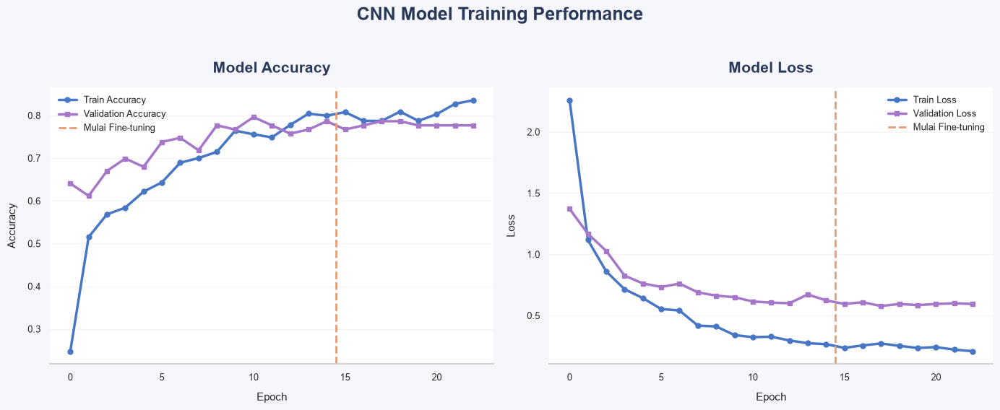

In [20]:

# ==========================================
# VISUALISASI TRAINING & VALIDATION CURVES
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
import os

# Style grafik
sns.set_theme(style="whitegrid", context="notebook")

split = history['split_epoch']

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

fig.patch.set_facecolor('#F5F7FC')

colors = {
    'train': '#4776C5',
    'val': '#A477C9',
    'split': '#E89B75'
}

metrics = [
    ('accuracy', 'Model Accuracy', 'Accuracy'),
    ('loss', 'Model Loss', 'Loss')
]

for a, (m, title, ylabel) in zip(ax, metrics):

    a.set_facecolor('#FFFFFF')

    # Training curve
    a.plot(
        history[m],
        color=colors['train'],
        marker='o',
        markersize=5,
        linewidth=2.5,
        label=f'Train {ylabel}'
    )

    # Validation curve
    a.plot(
        history[f'val_{m}'],
        color=colors['val'],
        marker='s',
        markersize=5,
        linewidth=2.5,
        label=f'Validation {ylabel}'
    )

    # Garis awal fine-tuning
    if 0 < split < len(history[m]):
        a.axvline(
            split - 0.5,
            color=colors['split'],
            linestyle='--',
            linewidth=2,
            label='Mulai Fine-tuning'
        )

    # Judul dan label
    a.set_title(
        title,
        fontsize=15,
        fontweight='bold',
        color='#293858',
        pad=15
    )

    a.set_xlabel('Epoch', fontsize=11, labelpad=10)
    a.set_ylabel(ylabel, fontsize=11, labelpad=10)

    # Tampilan grid
    a.grid(axis='y', alpha=0.2)
    a.grid(axis='x', visible=False)

    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.spines['left'].set_visible(False)

    a.legend(
        frameon=False,
        fontsize=9,
        loc='best'
    )

    a.tick_params(labelsize=9)

# Judul utama
fig.suptitle(
    'CNN Model Training Performance',
    fontsize=18,
    fontweight='bold',
    color='#293858',
    y=1.03
)

plt.tight_layout()

# Simpan grafik
plt.savefig(
    os.path.join(OUT_DIR, '4_training_curves.png'),
    dpi=300,
    bbox_inches='tight',
    facecolor=fig.get_facecolor()
)

plt.show()


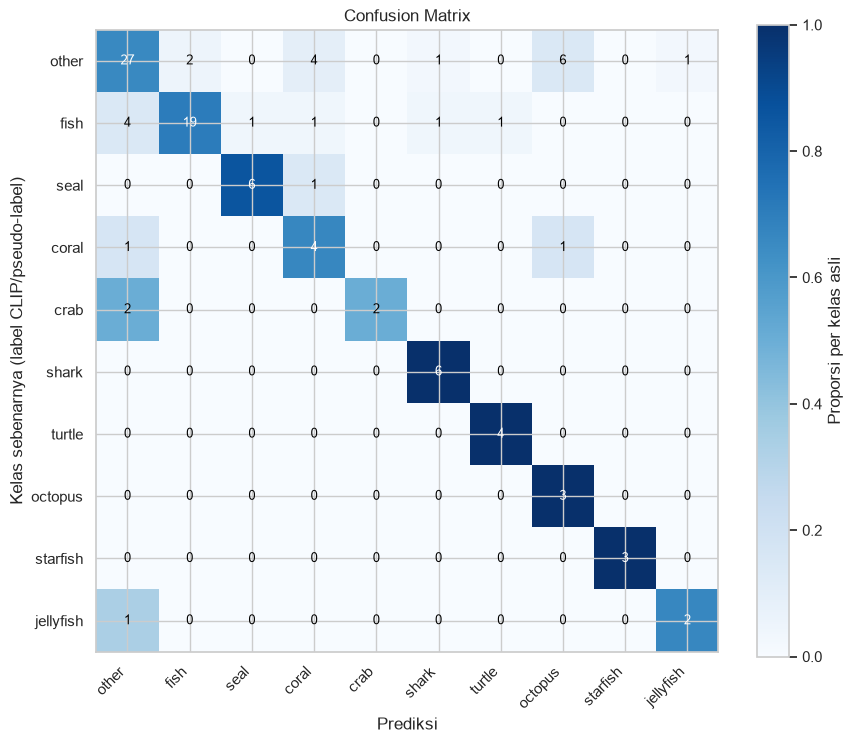

Kesalahan terbanyak (asli -> prediksi):
  other -> octopus: 6 gambar
  other -> coral: 4 gambar
  fish -> other: 4 gambar
  other -> fish: 2 gambar
  crab -> other: 2 gambar


In [21]:
cm = confusion_matrix(y_true, y_pred, labels=labels_idx)
np.save(os.path.join(OUT_DIR, 'confusion_matrix.npy'), cm)
cm_pct = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm_pct, cmap='Blues', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label='Proporsi per kelas asli')
ax.set_xticks(labels_idx); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right')
ax.set_yticks(labels_idx); ax.set_yticklabels(CLASS_NAMES)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm_pct[i, j] > .5 else 'black', fontsize=9)
ax.set_xlabel('Prediksi'); ax.set_ylabel('Kelas sebenarnya (label CLIP/pseudo-label)'); ax.set_title('Confusion Matrix')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '5_confusion_matrix.png'), dpi=120, bbox_inches='tight')
plt.show()

pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j])) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
pairs.sort(key=lambda t: -t[2])
print('Kesalahan terbanyak (asli -> prediksi):')
for a_, b_, n in pairs[:5]:
    print(f'  {a_} -> {b_}: {n} gambar')

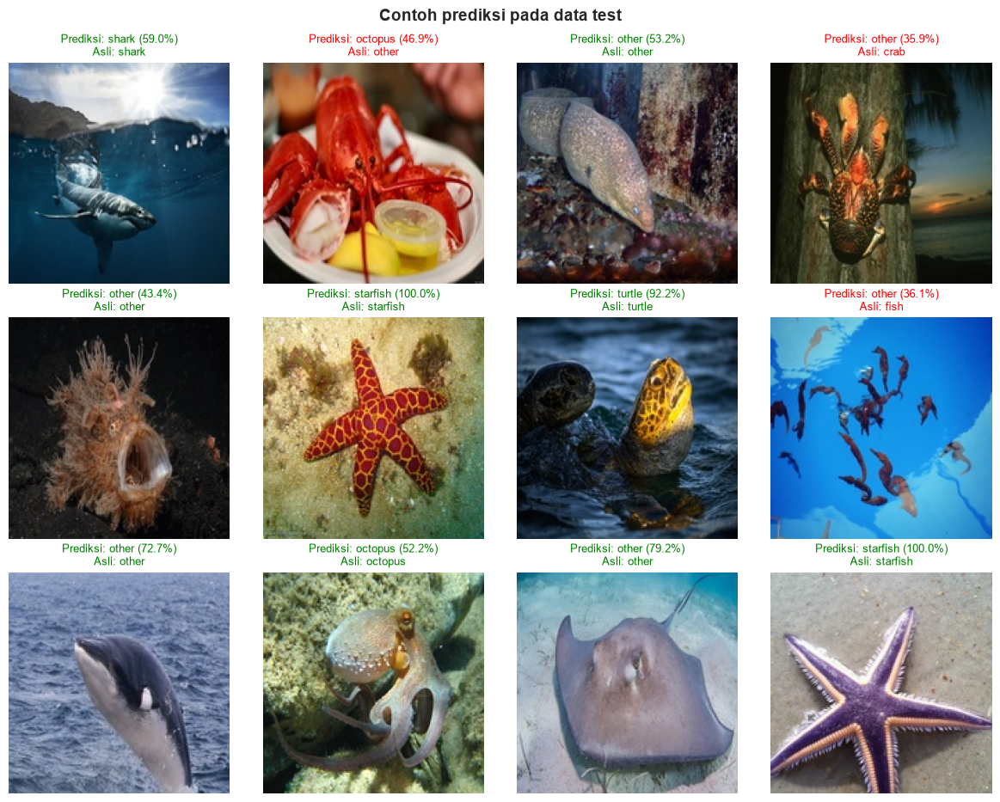

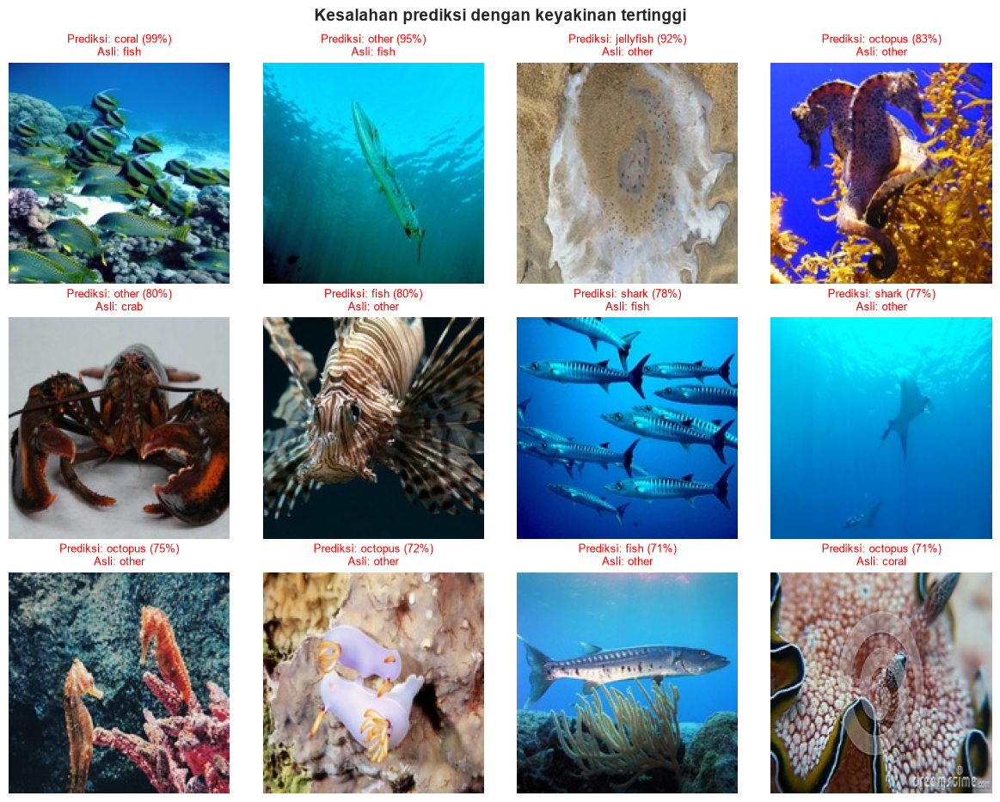

In [22]:
def load01(path):
    return np.asarray(Image.open(path).convert('RGB').resize(IMG_SIZE), dtype=np.float32) / 255.0

rs = np.random.default_rng(SEED).choice(len(test_df), size=min(12, len(test_df)), replace=False)
fig, axes = plt.subplots(3, 4, figsize=(12, 9.5))
for a, k in zip(axes.ravel(), rs):
    a.imshow(load01(test_df.loc[k, 'proc_path']))
    pr, tr = int(y_pred[k]), int(y_true[k])
    a.set_title(f'Prediksi: {CLASS_NAMES[pr]} ({probs[k, pr]*100:.1f}%)\nAsli: {CLASS_NAMES[tr]}',
                color='green' if pr == tr else 'red', fontsize=9)
    a.axis('off')
plt.suptitle('Contoh prediksi pada data test', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '6_sample_predictions.png'), dpi=110, bbox_inches='tight')
plt.show()

wrong = np.where(y_pred != y_true)[0]
if len(wrong):
    wrong = wrong[np.argsort(-probs[wrong, y_pred[wrong]])][:12]        # salah dengan keyakinan tertinggi
    fig, axes = plt.subplots(3, 4, figsize=(12, 9.5))
    for a in axes.ravel(): a.axis('off')
    for a, k in zip(axes.ravel(), wrong):
        a.imshow(load01(test_df.loc[k, 'proc_path']))
        a.set_title(f'Prediksi: {CLASS_NAMES[y_pred[k]]} ({probs[k, y_pred[k]]*100:.0f}%)\nAsli: {CLASS_NAMES[y_true[k]]}', color='red', fontsize=9)
    plt.suptitle('Kesalahan prediksi dengan keyakinan tertinggi', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, '7_misclassified.png'), dpi=110, bbox_inches='tight')
    plt.show()

In [23]:
print('Artefak di', os.path.abspath(OUT_DIR))
for f in sorted(os.listdir(OUT_DIR)):
    if os.path.isfile(os.path.join(OUT_DIR, f)):
        print(' -', f)

Artefak di c:\Users\ASUS\Downloads\Klasifikasi_Image_Menggunakan_CNN\output
 - 0_label_review_lowconf.png
 - 1_class_distribution.png
 - 2_sample_per_class.png
 - 2b_resized_folder_preview.png
 - 3_image_stats.png
 - 4_training_curves.png
 - 5_confusion_matrix.png
 - 6_sample_predictions.png
 - 7_misclassified.png
 - class_counts.csv
 - class_names.json
 - clip_probs.csv
 - config.json
 - confusion_matrix.npy
 - dataset_normalized.csv
 - eda_summary.json
 - final_oceanic_model.keras
 - history.json
 - labels.csv
 - meta.csv
 - metrics.json
 - metrics_table.csv
 - oceanic_best.keras
 - resized_folder_counts.csv
 - scan_info.json
 - split.csv
 - split_counts.csv


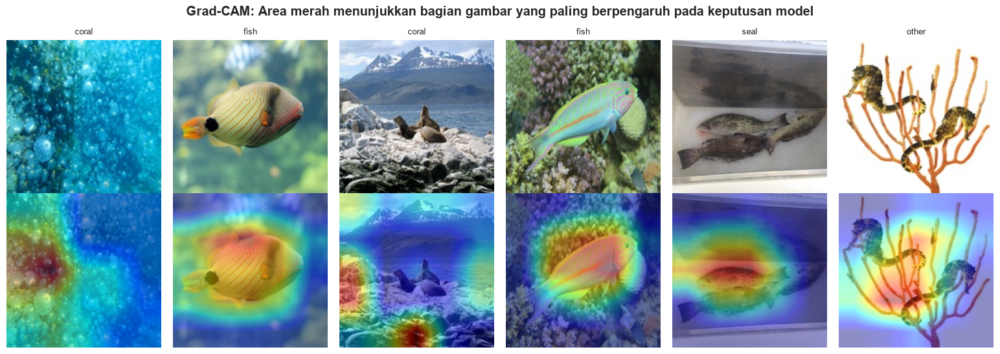

In [24]:
# ============ 6.4 GRAD-CAM ============

# Cari MobileNetV2 yang benar di dalam model
# agar tidak salah mengambil layer augmentation.
base_model = None

for layer in model.layers:
    if isinstance(layer, tf.keras.Model):
        try:
            layer.get_layer("out_relu")
            base_model = layer
            break
        except ValueError:
            continue

if base_model is None:
    raise ValueError(
        "MobileNetV2 dengan layer 'out_relu' tidak ditemukan. "
        "Periksa struktur model."
    )

# Ambil layer konvolusi terakhir MobileNetV2
conv_layer = base_model.get_layer("out_relu")

feat_model = tf.keras.Model(
    inputs=base_model.input,
    outputs=[conv_layer.output, base_model.output]
)


def gradcam(img, class_idx=None):
    """
    Membuat heatmap Grad-CAM.
    Input gambar menggunakan rentang piksel 0-1.
    """

    x = tf.convert_to_tensor(
        img[None].astype("float32")
    )

    with tf.GradientTape() as tape:

        # Preprocessing sama seperti saat training
        x = model.get_layer("augmentation")(
            x, training=False
        )

        x = model.get_layer("to_minus1_1")(x)

        # Ekstraksi fitur dari MobileNetV2
        conv, features = feat_model(
            x, training=False
        )

        # Teruskan fitur ke classifier head
        x = features

        backbone_position = model.layers.index(base_model)

        for layer in model.layers[backbone_position + 1:]:
            x = layer(x, training=False)

        predictions = x

        if class_idx is None:
            class_idx = tf.argmax(predictions[0])

        score = predictions[:, class_idx]

    # Hitung gradien
    grads = tape.gradient(score, conv)

    if grads is None:
        raise ValueError(
            "Gradien Grad-CAM tidak ditemukan."
        )

    # Hitung bobot dan heatmap
    weights = tf.reduce_mean(
        grads, axis=(1, 2), keepdims=True
    )

    cam = tf.nn.relu(
        tf.reduce_sum(weights * conv, axis=-1)
    )[0].numpy()

    cam = cam / (cam.max() + 1e-8)

    # Ubah ukuran heatmap sesuai ukuran gambar
    cam = tf.image.resize(
        cam[..., np.newaxis],
        IMG_SIZE
    ).numpy().squeeze()

    return cam, int(class_idx.numpy())


# ============ MENAMPILKAN 6 HASIL GRAD-CAM ============

n_show = min(6, len(test_df))

if n_show > 0:

    fig, axes = plt.subplots(
        2,
        n_show,
        figsize=(2.6 * n_show, 5.6),
        squeeze=False
    )

    for c in range(n_show):

        # Ambil gambar dari data test
        sample_path = test_df.iloc[c]["proc_path"]

        img = load01(sample_path)

        # Hitung Grad-CAM
        cam, k = gradcam(img)

        # Baris pertama: gambar asli
        axes[0, c].imshow(img)
        axes[0, c].axis("off")
        axes[0, c].set_title(
            f"{CLASS_NAMES[k]}",
            fontsize=9
        )

        # Baris kedua: gambar dengan heatmap
        axes[1, c].imshow(img)
        axes[1, c].imshow(
            cam,
            cmap="jet",
            alpha=0.45
        )
        axes[1, c].axis("off")

    plt.suptitle(
        "Grad-CAM: Area merah menunjukkan bagian gambar "
        "yang paling berpengaruh pada keputusan model",
        fontweight="bold"
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(OUT_DIR, "8_gradcam.png"),
        dpi=120,
        bbox_inches="tight"
    )

    plt.show()

else:
    print("Data test kosong. Grad-CAM tidak dapat ditampilkan.")